## menghubungkan neo4j

In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI  = "neo4j://localhost:7687"
AUTH = ("neo4j", "artasyanfcantik") 

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Terhubung ✔")

Terhubung ✔


## fungsi dan eksekusi 

In [3]:
from neo4j import GraphDatabase, RoutingControl

URI  = "neo4j://localhost:7687"
AUTH = ("neo4j", "artasyanfcantik")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


## hasil tutorial

In [4]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    rec, _, _ = driver.execute_query(
        "MATCH (n:Person) RETURN count(n) AS simpul", database_="neo4j")
    print("Jumlah simpul:", rec[0]["simpul"])

    rec, _, _ = driver.execute_query(
        "MATCH ()-[r:KNOWS]->() RETURN count(r) AS relasi", database_="neo4j")
    print("Jumlah relasi:", rec[0]["relasi"])

Jumlah simpul: 4
Jumlah relasi: 3


## Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**

Database **neo4j**, yaitu database default pada Neo4j. Hal ini terlihat dari
parameter `database_="neo4j"` pada pemanggilan `driver.execute_query(...)`.

**2. Sebutkan akses lain (sintaks DDL/DML Cypher) yang dapat mengakses database lain dalam 1 instance!**

- Lewat driver Python: mengganti parameter, misalnya `database_="namadb"` pada
  `execute_query`, atau `driver.session(database="namadb")`.
- Lewat Cypher: klausa `USE`, misalnya `USE namadb MATCH (n) RETURN n LIMIT 5`.
  Di Neo4j Browser atau cypher-shell juga bisa dengan perintah `:use namadb`.
- DDL manajemen database (dijalankan pada database `system`):
  `CREATE DATABASE namadb`, `SHOW DATABASES`, `DROP DATABASE namadb`.
- Catatan: database user tambahan hanya didukung pada Enterprise Edition
  (atau lisensi developer di Neo4j Desktop). Pada Community Edition hanya
  tersedia satu database user (`neo4j`) ditambah `system`.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf **berarah (directed)**, karena relasi `(:Person)-[:KNOWS]->(:Person)`
memiliki arah dari Arthur ke temannya. Graf ini juga **tak berbobot
(unweighted)**, **homogen** (satu label simpul `Person` dan satu tipe relasi
`KNOWS`), dan berbentuk **star** dengan Arthur sebagai pusat: 4 simpul dan
3 relasi. Karena memakai `MERGE`, menjalankan ulang tidak menghasilkan duplikat.
Relasinya tidak simetris: Arthur mengenal Merlin, tetapi tidak otomatis sebaliknya.

## reset database

In [5]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
    rec, _, _ = driver.execute_query(
        "MATCH (n) RETURN count(n) AS total", database_="neo4j")
    print("Sisa simpul:", rec[0]["total"])

Sisa simpul: 0


# IMPORT DATA RETAILROCKET

## Cek dataset

In [6]:
import pandas as pd

df = pd.read_csv("data/events.csv", nrows=5)
print(df)
print(df.dtypes)

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN
timestamp          int64
visitorid          int64
event             object
itemid             int64
transactionid    float64
dtype: object


## cek parameter 

In [ ]:
import os, sys
import pandas as pd
from tqdm.auto import tqdm
from neo4j import GraphDatabase

BOLT     = "neo4j://127.0.0.1:7687"
USER     = "neo4j"
PASSWORD = "artasyanfcantik"
SOURCE   = "data"
FILE     = "events.csv"     

## cek file dan koneksi

In [8]:
csv_file_path = os.path.join(SOURCE, FILE)

if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File '{csv_file_path}' tidak ditemukan!")

try:
    driver = GraphDatabase.driver(BOLT, auth=(USER, PASSWORD))
    driver.verify_connectivity()
    print("Koneksi berhasil")
except Exception as e:
    raise SystemExit(f"Gagal terhubung ke database: {e}")

Koneksi berhasil


## constraint

In [9]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

## Fungsi Cypher impor batch

In [10]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

## test sampel kecil

### Pesan merah adalah warning deprecation dari Neo4j (sintaks CALL subquery), bukan error; impor berhasil.

In [12]:
batch_size = 5000
N_TEST = 20000

def clean_tid(x):
    return "" if pd.isna(x) else str(int(x))

with driver.session() as session:
    create_constraints(session)

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size, nrows=N_TEST)
    total_chunks = (N_TEST // batch_size) + 1

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].apply(clean_tid)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor (tes) berhasil.")

Mengimpor Batch Data:   0%|          | 0/5 [00:00<?, ?it/s]

Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }} {position: line: 7, column: 5, offset: 139} for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'addtocart'\n        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'transaction'\n        CREATE (v)-[:BOUGHT {timestamp: row.timesta

Proses impor (tes) berhasil.


## verifikasi hasil test

In [13]:
rec, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah",
    database_="neo4j")
for r in rec: print(r["label"], r["jumlah"])

rec, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS rel, count(*) AS jumlah",
    database_="neo4j")
for r in rec: print(r["rel"], r["jumlah"])

Visitor 12108
Item 12196
VIEWED 38712
ADDED_TO_CART 938
BOUGHT 350


## reset setelah tes

In [14]:
driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
rec, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS total", database_="neo4j")
print("Sisa simpul:", rec[0]["total"])

Sisa simpul: 0


# SOAL UTS

## 2.1 WRANGLING DAN EDA

### 2.1.1 MUAT DATA DAN CEK RENTANG WAKTU

In [15]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

print("Jumlah baris :", len(df))
print("Awal data    :", df["datetime"].min())
print("Akhir data   :", df["datetime"].max())

Jumlah baris : 2756101
Awal data    : 2015-05-03 03:00:04.384000+00:00
Akhir data   : 2015-09-18 02:59:47.788000+00:00


### 2.1.2 filter fold dan simpan ke csv
#### sesuai pembagian fold masing"

In [ ]:
P1_START = pd.Timestamp("2015-05-24", tz="UTC")
P1_END   = pd.Timestamp("2015-07-24", tz="UTC") + pd.Timedelta(days=1)   
P2_START = pd.Timestamp("2015-08-02", tz="UTC")
P2_END   = pd.Timestamp("2015-08-17", tz="UTC") + pd.Timedelta(days=1)   

m_train = (df["datetime"] >= P1_START) & (df["datetime"] < P1_END)
m_test  = (df["datetime"] >= P2_START) & (df["datetime"] < P2_END)

df_train = df[m_train].copy()
df_test  = df[m_test].copy()
df_train["fold"] = "train"
df_test["fold"]  = "test"

print("Train:", len(df_train), "| visitor:", df_train.visitorid.nunique(), "| item:", df_train.itemid.nunique())
print("Test :", len(df_test),  "| visitor:", df_test.visitorid.nunique(),  "| item:", df_test.itemid.nunique())
print(df_train["event"].value_counts(), "\n")
print(df_test["event"].value_counts())

Train: 1293977 | visitor: 669200 | item: 170330
Test : 285400 | visitor: 164811 | item: 79363
event
view           1251067
addtocart        32242
transaction      10668
Name: count, dtype: int64 

event
view           275436
addtocart        7665
transaction      2299
Name: count, dtype: int64


In [17]:
cols = ["timestamp", "visitorid", "event", "itemid", "transactionid", "fold"]
df_all = pd.concat([df_train, df_test])[cols].copy()
df_all["transactionid"] = df_all["transactionid"].astype("Int64")

df_all.to_csv("data/events_filtered.csv", index=False)                           # satu file gabungan (jawaban soal no.2)
df_all[df_all.fold == "train"].to_csv("data/events_train.csv", index=False)      # untuk graf
df_all[df_all.fold == "test"].to_csv("data/events_test.csv", index=False)        # untuk evaluasi di 2.2

print("Tersimpan:", len(df_all), "baris")

Tersimpan: 1579377 baris


Hasil filter disimpan dalam tiga file di folder `data/`:

| File                    | Isi                                                       | Kegunaan                                         |
| :---------------------- | :-------------------------------------------------------- | :----------------------------------------------- |
| `events_filtered.csv` | Gabungan train dan test (1.579.377 baris, kolom `fold`) | **File jawaban soal No. 2**                |
| `events_train.csv`    | Hanya fold training (1.293.977 baris)                     | Diimpor ke Neo4j sebagai graf                    |
| `events_test.csv`     | Hanya fold testing (285.400 baris)                        | Dipakai sebagai *ground truth* pada Bagian 2.2 |

Jumlah baris `events_filtered.csv` (1.579.377) sama dengan 1.293.977 + 285.400, sehingga tidak ada baris yang hilang atau terduplikasi.

### 3. impor fold training ke neo4j

### Pesan merah adalah warning deprecation dari Neo4j (sintaks CALL subquery), bukan error; impor berhasil.

In [19]:
import os
from tqdm.auto import tqdm
from neo4j import GraphDatabase

BOLT, USER, PASSWORD = "neo4j://127.0.0.1:7687", "neo4j", "artasyanfcantik"
csv_file_path = "data/events_train.csv"

driver = GraphDatabase.driver(BOLT, auth=(USER, PASSWORD))
driver.verify_connectivity()

# Bersihkan dulu supaya relasi tidak ganda
driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")

batch_size   = 5000
total_rows   = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = (total_rows // batch_size) + 1
print("Total baris:", total_rows)

with driver.session() as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].apply(clean_tid)
        records = chunk.drop(columns=["fold"]).to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Total baris: 1293977


Mengimpor Batch Data:   0%|          | 0/259 [00:00<?, ?it/s]

Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }} {position: line: 7, column: 5, offset: 139} for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'addtocart'\n        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'transaction'\n        CREATE (v)-[:BOUGHT {timestamp: row.timesta

Proses impor berhasil.


### 2.1.3 Komposisi Subgraph dan CYPHER SQL Query

In [20]:
q_nodes = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
q_rels = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

rec, _, _ = driver.execute_query(q_nodes, database_="neo4j")
print("=== Simpul ===")
for r in rec: print(f"{r['jenis_simpul']:<10} {r['jumlah']:>10,}")

rec, _, _ = driver.execute_query(q_rels, database_="neo4j")
print("\n=== Relasi ===")
for r in rec: print(f"{r['jenis_relasi']:<15} {r['jumlah']:>10,}")

=== Simpul ===
Visitor       669,200
Item          170,330

=== Relasi ===
VIEWED           1,251,067
ADDED_TO_CART       32,242
BOUGHT              10,668


### Komposisi Subgraph (Fold Training)

Query dijalankan lewat Python API (`driver.execute_query`).

**1. Jumlah simpul per jenis**

```cypher
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
```

- `MATCH (n)` mencocokkan semua simpul tanpa memandang label.
- `labels(n)[0]` mengambil label simpul (`Visitor` atau `Item`).
- `count(n)` adalah fungsi agregasi. Cypher otomatis mengelompokkan hasilnya per label, jadi tidak perlu `GROUP BY`.
- `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.

**2. Jumlah relasi per jenis**

```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
```

- `MATCH ()-[r]->()` mencocokkan semua relasi berarah tanpa memandang simpul asal dan tujuan.
- `type(r)` mengambil nama relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`), lalu `count(r)` menghitung jumlah tiap tipe.

**Hasil**

| Jenis simpul | Jumlah | | Jenis relasi | Jumlah |
| :--- | ---: | --- | :--- | ---: |
| Visitor (User) | 669.200 | | VIEWED | 1.251.067 |
| Item | 170.330 | | ADDED_TO_CART | 32.242 |
| **Total** | **839.530** | | BOUGHT | 10.668 |
| | | | **Total** | **1.293.977** |

Total relasi (1.293.977) sama dengan jumlah baris `events_train.csv`, jadi impor berjalan lengkap. Grafnya bipartit (`Visitor → Item`), berarah, dan memiliki tiga jenis relasi.

## 2.1.4 - 2.1.5

### Ambil relasi dari Neo4j dan beri bobot

In [22]:
import numpy as np, pandas as pd
from scipy.sparse import csr_matrix

q = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitorid, i.itemId AS itemid, type(r) AS rel, count(r) AS n
"""
edges = driver.execute_query(
    q, database_="neo4j", result_transformer_=lambda res: res.to_df()
)

W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["rel"].map(W) * edges["n"]

# satu baris per pasangan (visitor, item), bobot dijumlahkan
agg = edges.groupby(["visitorid", "itemid"], as_index=False)["w"].sum()
print("Pasangan unik user-item:", len(agg))

Pasangan unik user-item: 1005835


### VSM user

In [23]:
u_codes, user_ids = pd.factorize(agg["visitorid"], sort=True)
i_codes, item_ids = pd.factorize(agg["itemid"], sort=True)
nU, nI = len(user_ids), len(item_ids)

U = csr_matrix((agg["w"].values, (u_codes, i_codes)), shape=(nU, nI))   # VSM User

def karakter(M, nama_baris, nama_kolom):
    nnz_baris = np.diff(M.indptr) if M.format == "csr" else None
    print(f"Shape            : {M.shape}  ({M.shape[0]:,} {nama_baris} x {M.shape[1]:,} {nama_kolom})")
    print(f"Dimensi vektor   : {M.shape[1]:,}")
    print(f"Non-zero         : {M.nnz:,}")
    print(f"Density          : {M.nnz / (M.shape[0]*M.shape[1]):.8%}")
    print(f"Sparsity         : {1 - M.nnz / (M.shape[0]*M.shape[1]):.6%}")
    print(f"Rata-rata nnz/baris : {nnz_baris.mean():.2f} | median {np.median(nnz_baris):.0f} | maks {nnz_baris.max():,}")
    print(f"Memori sparse    : {(M.data.nbytes + M.indices.nbytes + M.indptr.nbytes)/1e6:.1f} MB")
    print(f"Memori jika dense: {M.shape[0]*M.shape[1]*8/1e9:.1f} GB")

print("=== VSM USER ===")
karakter(U, "user", "item")

=== VSM USER ===
Shape            : (669200, 170330)  (669,200 user x 170,330 item)
Dimensi vektor   : 170,330
Non-zero         : 1,005,835
Density          : 0.00088243%
Sparsity         : 99.999118%
Rata-rata nnz/baris : 1.50 | median 1 | maks 2,169
Memori sparse    : 14.7 MB
Memori jika dense: 911.9 GB


- Matriks hampir seluruhnya kosong. Format *sparse* wajib dipakai, karena versi *dense* membutuhkan sekitar 912 GB sedangkan versi sparse hanya 14,7 MB.
- Median user hanya berinteraksi dengan **1 item**. Vektor user kebanyakan hanya punya satu elemen tidak nol, sehingga sulit dibandingkan antar user.
- Ada beberapa user ekstrem (maks. 2.169 item), yang kemungkinan besar bot atau *crawler*.

### VSM Item

In [24]:
I = U.T.tocsr()      # VSM Item

print("=== VSM ITEM ===")
karakter(I, "item", "user")

=== VSM ITEM ===
Shape            : (170330, 669200)  (170,330 item x 669,200 user)
Dimensi vektor   : 669,200
Non-zero         : 1,005,835
Density          : 0.00088243%
Sparsity         : 99.999118%
Rata-rata nnz/baris : 5.91 | median 2 | maks 1,624
Memori sparse    : 12.8 MB
Memori jika dense: 911.9 GB


- Isi datanya sama dengan VSM User, hanya orientasinya berbeda. Jumlah non-zero, density, dan sparsity identik.
- Perbedaan pentingnya ada pada **kepadatan per baris**: satu item rata-rata disentuh **5,91 user**, sedangkan satu user rata-rata hanya menyentuh 1,50 item. Vektor item membawa informasi lebih banyak untuk dibandingkan.
- Dimensi vektor item (669.200) jauh lebih besar daripada vektor user (170.330), tetapi karena sparse, ini tidak menjadi masalah memori.

### plot networkx

Sampel -> user: 64 | item: 12 | edge: 64


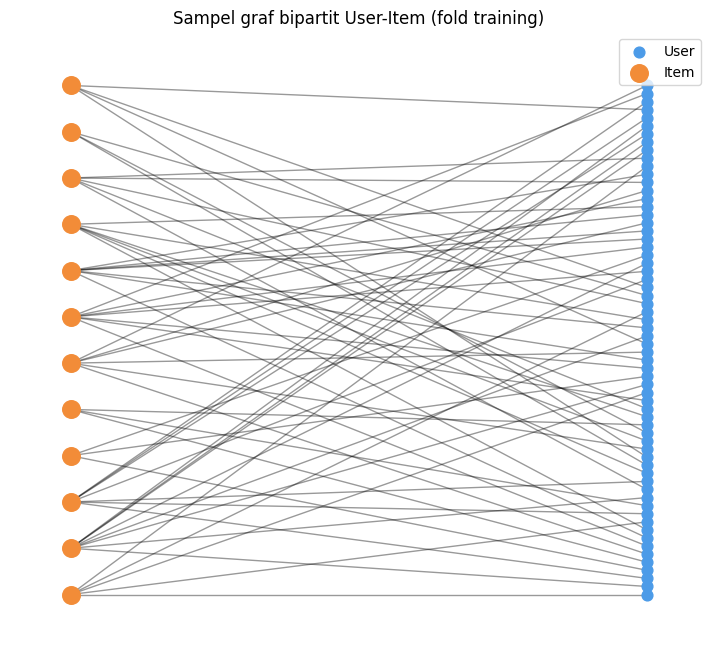

In [25]:
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

SEED = 42
rng = np.random.default_rng(SEED)

deg_item = agg.groupby("itemid").size()
kandidat = deg_item[(deg_item >= 3) & (deg_item <= 8)].index.to_numpy()
item_sampel = rng.choice(kandidat, size=12, replace=False)
sub = agg[agg["itemid"].isin(item_sampel)]

B = nx.Graph()
users_s = [f"U{u}" for u in sub["visitorid"].unique()]
items_s = [f"I{i}" for i in sub["itemid"].unique()]
B.add_nodes_from(users_s, bipartite=0)
B.add_nodes_from(items_s, bipartite=1)
B.add_weighted_edges_from(
    [(f"U{r.visitorid}", f"I{r.itemid}", r.w) for r in sub.itertuples()]
)
print("Sampel -> user:", len(users_s), "| item:", len(items_s), "| edge:", B.number_of_edges())

pos = nx.bipartite_layout(B, items_s)
plt.figure(figsize=(9, 8))
nx.draw_networkx_nodes(B, pos, nodelist=users_s, node_color="#4C9BE8", node_size=60, label="User")
nx.draw_networkx_nodes(B, pos, nodelist=items_s, node_color="#F28C38", node_size=160, label="Item")
nx.draw_networkx_edges(B, pos, alpha=0.4)
plt.legend(); plt.title("Sampel graf bipartit User-Item (fold training)"); plt.axis("off"); plt.show()

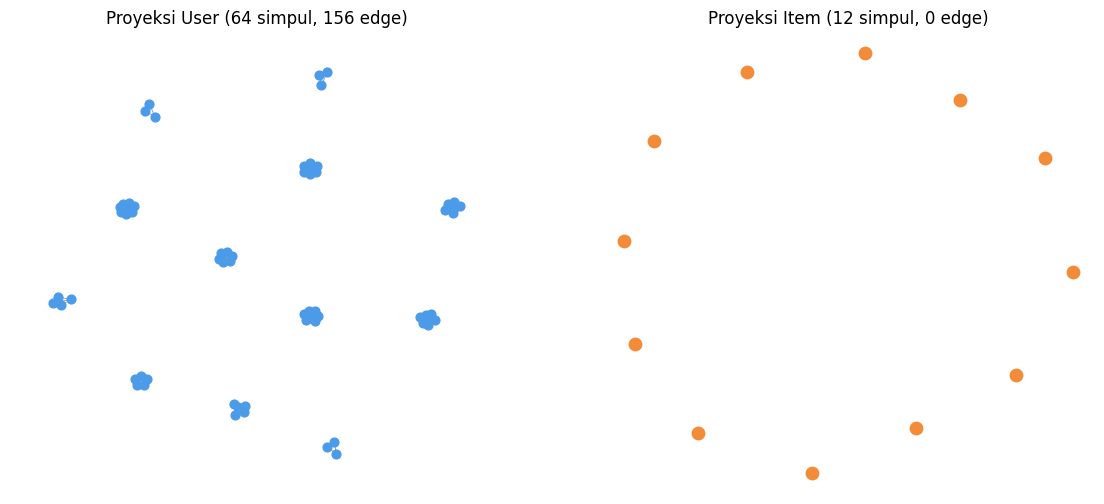

In [26]:
G_user = bipartite.projected_graph(B, users_s)    # user-user: berbagi item
G_item = bipartite.projected_graph(B, items_s)    # item-item: berbagi user

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
nx.draw(G_user, ax=ax[0], node_size=40, node_color="#4C9BE8", edge_color="gray", width=0.5)
ax[0].set_title(f"Proyeksi User ({G_user.number_of_nodes()} simpul, {G_user.number_of_edges()} edge)")
nx.draw(G_item, ax=ax[1], node_size=80, node_color="#F28C38", edge_color="gray", width=0.8)
ax[1].set_title(f"Proyeksi Item ({G_item.number_of_nodes()} simpul, {G_item.number_of_edges()} edge)")
plt.show()

### 2.1.6 bandingkan proyeksi

In [27]:
B_bin = U.copy(); B_bin.data[:] = 1

item_per_user = np.asarray(B_bin.sum(axis=1)).ravel().astype(np.int64)   # derajat user
user_per_item = np.asarray(B_bin.sum(axis=0)).ravel().astype(np.int64)   # derajat item

pair_user = int((user_per_item * (user_per_item - 1) // 2).sum())   # batas atas edge proyeksi user-user
pair_item = int((item_per_user * (item_per_user - 1) // 2).sum())   # batas atas edge proyeksi item-item

maks_user = nU * (nU - 1) // 2
maks_item = nI * (nI - 1) // 2

hasil = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Jumlah simpul": [nU, nI],
    "Pasangan terhubung (batas atas)": [pair_user, pair_item],
    "Maks. pasangan mungkin": [maks_user, maks_item],
    "Estimasi memori edge (GB)": [pair_user * 12 / 1e9, pair_item * 12 / 1e9],
})
hasil["Rasio terisi"] = hasil["Pasangan terhubung (batas atas)"] / hasil["Maks. pasangan mungkin"]
pd.set_option("display.float_format", "{:,.4f}".format)
display(hasil)

print("User: derajat maks", item_per_user.max(), "| median", np.median(item_per_user))
print("Item: derajat maks", user_per_item.max(), "| median", np.median(user_per_item))

,Proyeksi,Jumlah simpul,Pasangan terhubung (batas atas),Maks. pasangan mungkin,Estimasi memori edge (GB),Rasio terisi
0,User-User,669200,22509488,223913985400,0.2701,0.0001
1,Item-Item,170330,12468241,14506069285,0.1496,0.0009


User: derajat maks 2169 | median 1.0
Item: derajat maks 1624 | median 2.0


In [28]:
print("User dengan tepat 1 item :", f"{(item_per_user == 1).mean():.1%}")
print("Item dengan tepat 1 user :", f"{(user_per_item == 1).mean():.1%}")

User dengan tepat 1 item : 80.5%
Item dengan tepat 1 user : 41.1%


### Pilihan proyeksi: Item-Item

Proyeksi Item-Item lebih baik, dari sisi efisiensi dan efektivitas.

**Efisiensi.** Jumlah simpulnya hanya 170.330 (user: 669.200), pasangan terhubung
±12,5 juta (user: ±22,5 juta), dan estimasi memori edge 0,15 GB (user: 0,27 GB).
Selisih edge memang tidak dramatis (±1,8x), tetapi komputasi similarity dan
penyimpanan hasilnya lebih ringan.

**Efektivitas.** Pada VSM User, median user hanya berinteraksi dengan 1 item
(rata-rata 1,50), sehingga vektornya nyaris kosong. Kemiripan dua user hanya bisa
dihitung jika kebetulan memegang item yang sama, dan banyak user tidak punya
tetangga sama sekali. Pada VSM Item, rata-rata satu item disentuh 5,91 user,
sehingga vektornya lebih kaya sinyal. Rasio keterisian proyeksi item (0,09%)
juga ±9x lebih tinggi daripada proyeksi user (0,01%).

**Catatan.** Jumlah pasangan adalah batas atas, karena pasangan yang berbagi
lebih dari satu simpul terhitung berkali-kali. Hub (user dengan 2.169 item, item
dengan 1.624 user) menyumbang pasangan secara kuadratik dan menggelembungkan
angka itu. Selain itu, katalog item lebih stabil daripada populasi user
(user baru terus muncul), sehingga similarity item bisa dihitung sekali dan dipakai ulang.

### 2.1.7 Similarity di proyeksi Item

In [29]:
from sklearn.preprocessing import normalize
import scipy.sparse as sp

Inorm = normalize(I.astype(np.float32), norm="l2", axis=1)   # tiap baris item dinormalisasi
S = (Inorm @ Inorm.T).tocsr()                                # cosine item x item (sparse)
S.setdiag(0); S.eliminate_zeros()                            # buang similarity ke diri sendiri

print("Shape S :", S.shape)
print("Non-zero:", f"{S.nnz:,}", "(simetris, tiap pasangan terhitung 2x)")
print("Memori  :", f"{(S.data.nbytes + S.indices.nbytes + S.indptr.nbytes)/1e6:.0f} MB")

Shape S : (170330, 170330)
Non-zero: 22,690,216 (simetris, tiap pasangan terhitung 2x)
Memori  : 182 MB


Berdasarkan analisis No. 6, similarity dihitung pada proyeksi **Item-Item** dengan **cosine similarity**:

1. Tiap vektor item (baris `I`) dinormalisasi L2 (`normalize(..., norm="l2")`) sehingga panjangnya 1.
2. Perkalian `Inorm @ Inorm.T` menghasilkan matriks `S` berukuran (170.330 × 170.330). Nilai `S[a,b]` adalah cosine antara item a dan b, antara 0 (tidak mirip) sampai 1 (identik).
3. Diagonal dikosongkan (`setdiag(0)`), karena similarity item dengan dirinya sendiri tidak berguna.

**Hasil:**

- Non-zero: **22.690.216** (simetris, sehingga tiap pasangan terhitung dua kali, atau sekitar 11,3 juta pasangan unik).
- Angka ini wajar dan tidak melebihi batas atas 12,47 juta pada Blok 11.
- Memori hanya 182 MB, karena `S` disimpan *sparse*. Pasangan item yang tidak punya user bersama bernilai 0 dan tidak disimpan.

### 2.1.7a Pilih record acuan dan lihat 5 tetangga teratas

In [30]:
rng = np.random.default_rng(42)
kandidat = np.where((user_per_item >= 20) & (user_per_item <= 200))[0]
ref_idx  = int(rng.choice(kandidat))
ref_item = int(item_ids[ref_idx])
print("Item acuan:", ref_item, "| jumlah user:", user_per_item[ref_idx])

row = S.getrow(ref_idx)
top = np.argsort(-row.data)[:5]
hasil5 = pd.DataFrame({
    "itemid"    : item_ids[row.indices[top]],
    "similarity": row.data[top].round(4),
    "jumlah_user": user_per_item[row.indices[top]],
})
display(hasil5)

Item acuan: 44319 | jumlah user: 23


,itemid,similarity,jumlah_user
0,202077,0.3451,16
1,257218,0.3050,1
2,82283,0.3050,1
3,188982,0.3050,1
4,120931,0.3050,1


### ambil top-K tetangga per item

In [31]:
K = 10
rows, cols, vals = [], [], []
for r in range(S.shape[0]):
    s, e = S.indptr[r], S.indptr[r+1]
    if e == s: continue
    d, c = S.data[s:e], S.indices[s:e]
    idx = np.argpartition(-d, K)[:K] if len(d) > K else np.arange(len(d))
    rows.extend([r]*len(idx)); cols.extend(c[idx]); vals.extend(d[idx])

sim_df = pd.DataFrame({
    "item_a": item_ids[rows], "item_b": item_ids[cols],
    "similarity": np.round(vals, 4),
})
print("Baris similarity top-K:", f"{len(sim_df):,}")
sim_df.to_csv("data/item_similarity_topk.csv", index=False)

Baris similarity top-K: 628,147


### 2.1.7b tulis similarity ke graf

In [42]:
def set_nusers(tx, batch):
    tx.run("""
    UNWIND $batch AS row
    MATCH (i:Item {itemId: row.itemId})
    SET i.nUsers = row.nUsers
    """, batch=batch)

def write_sim(tx, batch):
    tx.run("""
    UNWIND $batch AS row
    MATCH (a:Item {itemId: row.item_a})
    MATCH (b:Item {itemId: row.item_b})
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.similarity = row.similarity
    """, batch=batch)

# 1) nUsers
rows_u = [{"itemId": int(i), "nUsers": int(n)} for i, n in zip(item_ids, user_per_item)]
with driver.session() as session:
    for s in tqdm(range(0, len(rows_u), 10000), desc="nUsers"):
        session.execute_write(set_nusers, rows_u[s:s+10000])

# 2) SIMILAR_TO
rows_s = [{"item_a": int(a), "item_b": int(b), "similarity": float(v)}
          for a, b, v in zip(sim_df.item_a, sim_df.item_b, sim_df.similarity)]
with driver.session() as session:
    for s in tqdm(range(0, len(rows_s), 5000), desc="SIMILAR_TO"):
        session.execute_write(write_sim, rows_s[s:s+5000])

rec, _, _ = driver.execute_query(
    "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n", database_="neo4j")
print("Relasi SIMILAR_TO:", rec[0]["n"])

nUsers:   0%|          | 0/18 [00:00<?, ?it/s]

SIMILAR_TO:   0%|          | 0/126 [00:00<?, ?it/s]

Relasi SIMILAR_TO: 628147


### 2.1.8 kondisi sebelum

In [ ]:
ref_item = 44319   

for q, ket in [
    ("MATCH (n) RETURN labels(n)[0] AS x, count(*) AS jumlah", "Simpul"),
    ("MATCH ()-[r]->() RETURN type(r) AS x, count(*) AS jumlah", "Relasi"),
]:
    rec, _, _ = driver.execute_query(q, database_="neo4j")
    print(f"--- {ket} SEBELUM similarity ---")
    for r in rec: print(f"{r['x']:<15} {r['jumlah']:>10,}")

--- Simpul SEBELUM similarity ---
Visitor            669,200
Item               170,330
--- Relasi SEBELUM similarity ---
VIEWED           1,251,067
ADDED_TO_CART       32,242
BOUGHT              10,668


![alt text](<Tangkapan Layar 2026-10-20 pukul 19.48.18-1.png>)

### kondisi sesudah

In [44]:
for q, ket in [
    ("MATCH (n) RETURN labels(n)[0] AS x, count(*) AS jumlah", "Simpul"),
    ("MATCH ()-[r]->() RETURN type(r) AS x, count(*) AS jumlah", "Relasi"),
]:
    rec, _, _ = driver.execute_query(q, database_="neo4j")
    print(f"--- {ket} SESUDAH similarity ---")
    for r in rec: print(f"{r['x']:<15} {r['jumlah']:>10,}")

--- Simpul SESUDAH similarity ---
Visitor            669,200
Item               170,330
--- Relasi SESUDAH similarity ---
VIEWED           1,251,067
ADDED_TO_CART       32,242
BOUGHT              10,668
SIMILAR_TO         628,147


![alt text](<Tangkapan Layar 2026-10-20 pukul 19.50.16.png>)

# 2.2 Analytics

## Pilih user acak

In [45]:
uidx = pd.Index(user_ids)

test_gt = (df_test[df_test.visitorid.isin(user_ids) & df_test.itemid.isin(item_ids)]
           .groupby("visitorid")["itemid"].apply(set))

n_train_items = np.diff(U.indptr)

def items_train(r):
    return set(item_ids[U.indices[U.indptr[r]:U.indptr[r+1]]])

cands = []
for u, its in test_gt.items():
    r = uidx.get_loc(u)
    if n_train_items[r] >= 3 and (its - items_train(r)):
        cands.append(int(u))
cands = sorted(cands)                       # urutan tetap -> reproducible

rng = np.random.default_rng(42)             # seed tetap
target = int(rng.choice(cands))
r_target = uidx.get_loc(target)

print("Jumlah kandidat user:", len(cands))
print("User terpilih       :", target)
print("Item di training    :", n_train_items[r_target])
print("Item relevan (test) :", test_gt[target] - items_train(r_target))

Jumlah kandidat user: 2154
User terpilih       : 132066
Item di training    : 69
Item relevan (test) : {465211}


### 2.2.1a & 2.2.1b Skrip rekomendasi KNN k=5 dan 3 item yang diiklankan

In [46]:
def recommend(r, k=5, n=5, min_users=2):
    s, e = U.indptr[r], U.indptr[r+1]
    its, w = U.indices[s:e], U.data[s:e]
    seen = set(its)
    scores = {}
    for it, wt in zip(its, w):
        a, b = S.indptr[it], S.indptr[it+1]
        d, c = S.data[a:b], S.indices[a:b]
        m = user_per_item[c] >= min_users
        d, c = d[m], c[m]
        if len(d) == 0:
            continue
        top = np.argsort(-d, kind="stable")[:k]          # k tetangga terdekat
        for cc, dd in zip(c[top], d[top]):
            scores[cc] = scores.get(cc, 0.0) + wt * dd
    ranked = sorted(((c, sc) for c, sc in scores.items() if c not in seen),
                    key=lambda x: (-x[1], item_ids[x[0]]))
    return [(int(item_ids[c]), float(sc)) for c, sc in ranked[:n]]

rekom = recommend(r_target, k=5, n=5)
tabel = pd.DataFrame(rekom, columns=["itemid", "skor"])
tabel["diiklankan"] = ["ya" if i < 3 else "" for i in range(len(tabel))]
display(tabel)

print("3 item yang diiklankan:", [i for i, _ in rekom[:3]])

,itemid,skor,diiklankan
0,265571,9.2690,ya
1,334041,6.8944,ya
2,386518,4.1957,ya
3,373700,3.7306,
4,438823,3.3261,


3 item yang diiklankan: [265571, 334041, 386518]



- **User terpilih:** Visitor ID 132066 (69 item di training).
- **Metode:** Item-based KNN. Untuk tiap item milik user diambil k = 5 tetangga terdekat dari matriks cosine similarity (hanya item dengan minimal 2 user), lalu skor kandidat dijumlahkan sebagai bobot interaksi × similarity. Item yang sudah pernah diakses dibuang.
- **3 item yang diiklankan (k=5):** [265571, 334041, 386518].

| Peringkat | Item ID | Skor | Keterangan |
| :---: | :---: | ---: | :--- |
| 1 | 265571 | 9,2690 | Diiklankan |
| 2 | 334041 | 6,8944 | Diiklankan |
| 3 | 386518 | 4,1957 | Diiklankan |
| 4 | 373700 | 3,7306 | Pelengkap Top-5 |
| 5 | 438823 | 3,3261 | Pelengkap Top-5 |

### 2.2.1a & 2.2.1b Hit@5 dan NDCG@5

In [47]:
def hit_ndcg_at_k(rekom_ids, relevan, k=5):
    rekom_ids = rekom_ids[:k]
    hits = [1 if i in relevan else 0 for i in rekom_ids]
    hit = int(any(hits))
    dcg = sum(h / np.log2(pos + 2) for pos, h in enumerate(hits))
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(relevan), k)))
    return hit, (dcg / idcg if idcg > 0 else 0.0)

relevan = test_gt[target] - items_train(r_target)
hit, ndcg = hit_ndcg_at_k([i for i, _ in rekom], relevan, k=5)
print(f"Hit@5  = {hit}")
print(f"NDCG@5 = {ndcg:.4f}")

Hit@5  = 0
NDCG@5 = 0.0000


**Top-5 rekomendasi:** [265571, 334041, 386518, 373700, 438823]

| Metrik | Rumus | Hasil |
| :--- | :--- | :---: |
| **Hit@5** | 1 jika ada item relevan di Top-5, selain itu 0 | **0,0000** |
| **NDCG@5** | DCG@5 / IDCG@5, dengan DCG = Σ rel_i / log₂(i+1) | **0,0000** |

## cek

In [48]:
j = int(np.where(item_ids == 465211)[0][0]) if 465211 in item_ids else None
print("465211 ada di graf training:", j is not None)
if j is not None:
    print("Jumlah user training      :", user_per_item[j])
    print("Lolos filter min_users=2  :", user_per_item[j] >= 2)

465211 ada di graf training: True
Jumlah user training      : 15
Lolos filter min_users=2  : True
